In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("Lab6_vibrations.csv")
features = ["vib_x", "vib_y", "machine_hours"]
X = df[features].to_numpy(float)
y = df["faulty"].to_numpy()
idx = np.random.default_rng(0).permutation(len(y))
te, tr = idx[:100], idx[100:]
X_train, y_train = X[tr], y[tr]
X_test, y_test = X[te], y[te]
print("train:", X_train.shape, " test:", X_test.shape) # (300, 3) (100, 3)

train: (300, 3)  test: (100, 3)


In [4]:
df.head()

,vib_x,vib_y,machine_hours,faulty
0,3.074,-0.823,44742.4,1
1,4.017,1.021,47952.9,1
2,1.701,-0.421,14633.9,0
3,1.018,2.995,40585.6,1
4,-0.266,0.664,10181.2,0


[0       True
1       True
2      False
3       True
4      False
       ...  
395     True
396    False
397     True
398    False
399     True
Name: faulty, Length: 400, dtype: bool]


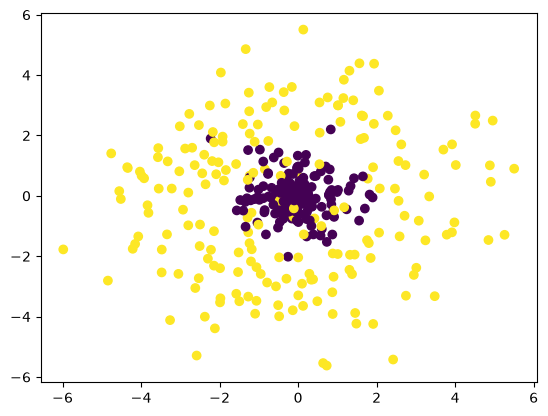

In [8]:
mask=[df['faulty']==1]
print(mask)
plt.scatter(df['vib_x'],df['vib_y'],c=mask)

[0       True
1       True
2      False
3       True
4      False
       ...  
395     True
396    False
397     True
398    False
399     True
Name: faulty, Length: 400, dtype: bool]


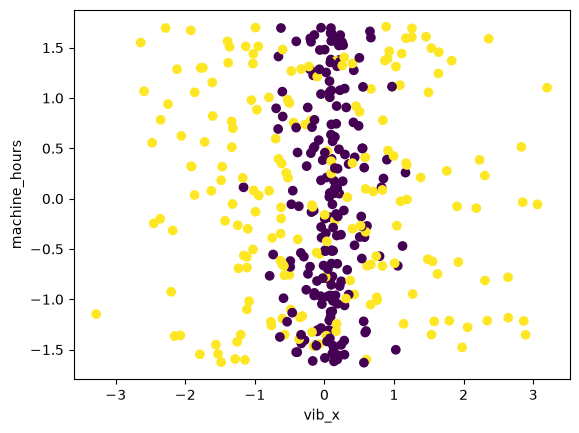

In [42]:
cf=df.copy()
cf['vib_x']=(cf['vib_x']-np.mean(cf['vib_x']))/np.std(cf['vib_x'])
cf['machine_hours']=(cf['machine_hours']-np.mean(cf['machine_hours']))/np.std(cf['machine_hours'])
mask=[cf['faulty']==1]
print(mask)
# plt.scatter(cf['vib_x'],df['machine_hours'],c=mask)
plt.scatter(cf['vib_x'],cf['machine_hours'],c=mask)
plt.xlabel("vib_x")
plt.ylabel("machine_hours")
plt.show()

In [10]:
for name, s in zip(features, X_train.std(axis=0)):
    print(f"{name:15s}{s:12.3f}")

vib_x                 1.733
vib_y                 1.736
machine_hours     14590.484


In [14]:

def pairwise_distances(X, Y):
   
    return np.sqrt(abs(
        np.sum(X**2, axis=1, keepdims=True)
        + np.sum(Y**2, axis=1)
        - 2 * np.dot(X, Y.T)
    ))


def standardise(X_train, X_test):
    
    mu = np.mean(X_train, axis=0)
    sigma = np.std(X_train, axis=0)
    Z_train = (X_train - mu) / sigma
    Z_test = (X_test - mu) / sigma
    return Z_train, Z_test

In [15]:
def knn_predict(X_train, y_train, X_query, k):
    dists = pairwise_distances(X_query, X_train)
    nearest_indices = np.argsort(dists, axis=1)[:, :k]  
    neighbor_labels = y_train[nearest_indices]

    preds = (np.mean(neighbor_labels, axis=1) > 0.5).astype(int)
    return preds


train_preds = knn_predict(X_train, y_train, X_train, k=1)
perfect_match = np.all(train_preds == y_train)
print(f"Task 1 Sanity Check (k=1 on training set perfect match): {perfect_match}")

Task 1 Sanity Check (k=1 on training set perfect match): True


In [17]:

Z_train, Z_test = standardise(X_train, X_test)
raw_preds_7 = knn_predict(X_train, y_train, X_test, k=7)
raw_acc = np.mean(raw_preds_7 == y_test)
std_preds_7 = knn_predict(Z_train, y_train, Z_test, k=7)
std_acc = np.mean(std_preds_7 == y_test)
print(f"\nTest Accuracy at k=7 (Raw features): {raw_acc:.4f}")
print(f"Test Accuracy at k=7 (Standardised features): {std_acc:.4f}")


Test Accuracy at k=7 (Raw features): 0.5700
Test Accuracy at k=7 (Standardised features): 0.9400


In [31]:
def k_fold_cv_knn(X, y, k, folds=5, seed=0):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(y))
    fold_sizes = np.full(folds, len(y) // folds)

    print(fold_sizes)
    accuracies = []
    current = 0
    for fold_size in fold_sizes:
        start, stop = current, current + fold_size
        val_idx = indices[start:stop]
        train_idx = np.concatenate([indices[:start], indices[stop:]])
        X_tr, y_tr = X[train_idx], y[train_idx]
        X_val, y_val = X[val_idx], y[val_idx]
        mu = np.mean(X_tr, axis=0)
        sigma = np.std(X_tr, axis=0)
        X_tr_std = (X_tr - mu) / sigma
        X_val_std = (X_val - mu) / sigma
        preds = knn_predict(X_tr_std, y_tr, X_val_std, k)
        acc = np.mean(preds == y_val)
        accuracies.append(acc)
        current = stop

    return np.mean(accuracies)
#k_list = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51, 75]
k_list = [i for i in range(1,100)]
cv_results = []
for k_val in k_list:
    cv_acc = k_fold_cv_knn(X_train, y_train, k_val, folds=5, seed=0)
    cv_results.append((k_val, cv_acc))
cv_df = pd.DataFrame(cv_results, columns=["k", "CV_Accuracy"])
print(cv_df)
best_row = cv_df.loc[cv_df["CV_Accuracy"].idxmax()]
best_k = int(best_row["k"])
print(f"\nBest k: {best_k} with CV Accuracy: {best_row['CV_Accuracy']:.4f}")
print("\nTest Accuracies:")
for k_val in [best_k, 1, 75]:
    preds = knn_predict(Z_train, y_train, Z_test, k=k_val)
    acc = np.mean(preds == y_test)
    print(f"k = {k_val:2d} -> Test Accuracy: {acc:.4f}")

[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 60]
[60 60 60 60 6

In [27]:
cv_df.head(10)

,k,CV_Accuracy
0,1,0.846667
1,2,0.853333
2,3,0.873333
3,4,0.876667
4,5,0.886667
5,6,0.896667
6,7,0.903333
7,8,0.900000
8,9,0.903333
9,10,0.893333


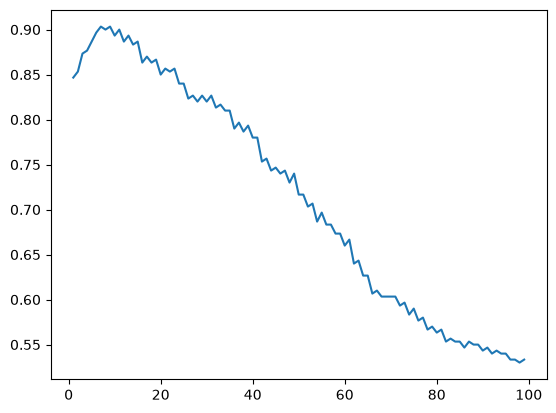

In [25]:
plt.plot(cv_df['k'],cv_df['CV_Accuracy'])